# Synthèse croisée du narratif fictif

Cette synthèse confronte Ecology, Logistics, Health et Public Records sans modifier
les analyses des autres membres. La consigne demande de reconstituer un narratif
caché, pas nécessairement une phrase chiffrée. Toutes les personnes, organisations
et observations appartiennent au jeu synthétique du projet.

Nous distinguons les relations retrouvées par des clés ou plusieurs attributs,
les affirmations explicites de documents et les interprétations non démontrées.
Une source qui se déclare concluante ne dispense pas de vérifier ses références.
Les versions actuelles des données, les unités et les discordances sont conservées.

**Usage de l'IA générative.** Une assistance a aidé à proposer et corriger le code,
à explorer les recoupements et à rédiger les commentaires. Les calculs de cette
synthèse ont été réexécutés indépendamment et les limites sont documentées.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

fichiers_recit = {
    'sites': 'ecology/monitoring_sites.csv', 'bats': 'ecology/bat_surveys.csv',
    'rapports': 'ecology/environmental_field_reports.csv', 'appareils': 'ecology/monitoring_device_operations.csv',
    'acces': 'public_records/site_access_case_events.csv',
    'reglementaire': 'public_records/regulatory_case_events.csv', 'entites': 'public_records/registered_entities.csv',
    'licences_facilites': 'public_records/licensed_facilities.csv', 'licences_professionnels': 'public_records/licensed_professionals.csv',
    'dirigeants': 'public_records/officer_filings.csv', 'nominations': 'public_records/public_appointments.csv',
    'publications': 'public_records/public_and_investigative_documents.csv', 'memos': 'public_records/institutional_memos.csv',
    'partenaires': 'logistics/erp_business_partners.csv', 'facilites': 'logistics/erp_facilities.csv',
    'expeditions': 'logistics/shipments.csv', 'ajustements': 'logistics/inventory_adjustments.csv',
    'stocks': 'logistics/inventory_month_end.csv', 'receptions': 'logistics/goods_receipts.csv',
    'procedures': 'health/clinical_procedures.csv', 'patients': 'health/patient_administration.csv',
    'observations': 'health/clinical_observations.csv', 'notes': 'health/clinical_notes.csv'
}
sources_recit = {}
audit_recit = []
for nom, chemin in fichiers_recit.items():
    brut = pd.read_csv(Path('data') / chemin)
    sources_recit[nom] = brut.drop_duplicates().copy()
    audit_recit.append({'source': nom, 'lignes_brutes': len(brut), 'doublons_exacts': brut.duplicated().sum(), 'lignes_conservees': len(sources_recit[nom])})
display(pd.DataFrame(audit_recit))

def normaliser_nom_recit(serie):
    return serie.astype('string').str.lower().str.replace(r'^dr\.?\s+', '', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()

def dates_recit(serie):
    valeurs = serie.astype('string').str.strip()
    sortie = pd.Series(pd.NaT, index=serie.index, dtype='datetime64[us]')
    reconnus = valeurs.isna()
    formats = [
        (r'\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}', '%Y-%m-%dT%H:%M:%S'),
        (r'\d{4}-\d{2}-\d{2}', '%Y-%m-%d'),
        (r'\d{4}/\d{2}/\d{2} \d{2}:\d{2}:\d{2}', '%Y/%m/%d %H:%M:%S'),
        (r'\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2}', '%d/%m/%Y %H:%M:%S'),
        (r'\d{4}/\d{2}/\d{2}', '%Y/%m/%d'),
        (r'\d{2}/\d{2}/\d{4}', '%d/%m/%Y'),
        (r'\d{2}-[A-Za-z]{3}-\d{4} \d{2}:\d{2}:\d{2}', '%d-%b-%Y %H:%M:%S'),
        (r'\d{2}-[A-Za-z]{3}-\d{4}', '%d-%b-%Y')
    ]
    for motif, format_date in formats:
        masque = valeurs.str.fullmatch(motif, na=False)
        sortie.loc[masque] = pd.to_datetime(valeurs.loc[masque], format=format_date, errors='raise')
        reconnus = reconnus | masque
    if not reconnus.all():
        raise ValueError('Dates à examiner : ' + str(valeurs.loc[~reconnus].unique()))
    return sortie

def nombres_recit(serie, unite=None):
    valeurs = serie.astype('string').str.strip().str.replace(',', '.', regex=False)
    if unite is not None:
        valeurs = valeurs.str.replace(r'\s+' + re.escape(unite) + r'$', '', regex=True)
    return pd.to_numeric(valeurs, errors='raise')

def document_recit(identifiant):
    for source in ['publications', 'memos', 'notes', 'rapports']:
        selection = sources_recit[source].loc[sources_recit[source]['document_id'].eq(identifiant)]
        if len(selection):
            assert len(selection) == 1
            return source, selection.iloc[0]
    raise KeyError(identifiant)

def lire_document_recit(identifiant):
    source, ligne = document_recit(identifiant)
    titre = ligne.get('title', ligne.get('subject_line', identifiant))
    display(Markdown('### ' + identifiant + ' — ' + str(titre)))
    display(Markdown('Source : `data/' + fichiers_recit[source] + '`, date : ' + str(ligne['document_date'])))
    display(Markdown(ligne['text']))

,source,lignes_brutes,doublons_exacts,lignes_conservees
0,sites,64,0,64
1,bats,4994,2,4992
2,rapports,30,0,30
3,appareils,4994,2,4992
4,acces,413,1,412
5,reglementaire,233,1,232
6,entites,24,0,24
7,licences_facilites,3,0,3
8,licences_professionnels,53,0,53
9,dirigeants,136,1,135


## 1. Ponts entre référentiels : ne pas confondre les codes locaux

Les licences Health, les codes ERP et les numéros d'enregistrement public ne sont
pas identiques. Nous relions d'abord une organisation par son numéro public.
Pour les établissements Asterion, nous vérifions aussi le nom normalisé et
l'organisation exploitante. Cette méthode ne fusionne pas deux établissements
sur la seule proximité géographique.

In [2]:
partenaires_recit = sources_recit['partenaires']
entites_recit = sources_recit['entites']
assert partenaires_recit['partner_code'].is_unique and entites_recit['registration_number'].is_unique
facilites_recit = sources_recit['facilites'].merge(partenaires_recit[['partner_code', 'external_registration_number']], left_on='operating_partner_code', right_on='partner_code', how='left', validate='many_to_one')
facilites_recit['nom_normalise'] = normaliser_nom_recit(facilites_recit['facility_name'])
licences_facilites_recit = sources_recit['licences_facilites'].copy()
licences_facilites_recit['nom_normalise'] = normaliser_nom_recit(licences_facilites_recit['facility_name'])
pont_facilites_recit = licences_facilites_recit.merge(facilites_recit, left_on=['operating_organization_registration', 'nom_normalise'], right_on=['external_registration_number', 'nom_normalise'], how='left', validate='one_to_one', suffixes=('_licence','_erp'))
display(pont_facilites_recit.loc[pont_facilites_recit['operating_organization_registration'].eq('REG-VLN-01002'), ['facility_license_number', 'facility_name_licence', 'operating_organization_registration', 'facility_code', 'operating_partner_code']])
display(partenaires_recit.loc[partenaires_recit['external_registration_number'].isin(['REG-AVL-01013','REG-VLN-01001','REG-VLN-01002']), ['partner_code','partner_name','external_registration_number']])

,facility_license_number,facility_name_licence,operating_organization_registration,facility_code,operating_partner_code
0,FAC-VLN-101,Asterion Central Clinical Campus,REG-VLN-01002,FCL-1010,BP-30021
1,FAC-AVL-201,Asterion Avelora Executive Clinic,REG-VLN-01002,FCL-1007,BP-30021


,partner_code,partner_name,external_registration_number
20,BP-30021,Asterion Clinical Institute,REG-VLN-01002
55,BP-30056,Horizon Field Research Cooperative,REG-AVL-01013
77,BP-30078,Meridian BioLogistics,REG-VLN-01001


## 2. Deux flux récurrents, avec un acteur de raccordement

Nous reproduisons les sous-ensembles repérés par Logistics à partir des motifs
déclarés, puis examinons leurs partenaires, destinations et unités. Une même
entreprise dans deux flux constitue un raccordement organisationnel, pas la preuve
qu'un même contenu a traversé toutes les étapes.

In [3]:
expeditions_recit = sources_recit['expeditions'].copy()
expeditions_recit['depart'] = dates_recit(expeditions_recit['dispatch_time'])
expeditions_recit['arrivee'] = dates_recit(expeditions_recit['arrival_time'])
motif_clinique_recit = 'temperature-controlled clinical programme delivery'
motif_ecologique_recit = 'environmental and wildlife reference materials'
flux_cibles_recit = expeditions_recit.loc[expeditions_recit['declared_purpose'].isin([motif_clinique_recit, motif_ecologique_recit])].copy()
for role in ['sender','receiver','carrier']:
    flux_cibles_recit[role+'_name'] = flux_cibles_recit[role+'_partner_code'].map(partenaires_recit.set_index('partner_code')['partner_name'])
display(flux_cibles_recit.groupby('declared_purpose').agg(nombre_lignes=('shipment_number','size'), expeditions_distinctes=('shipment_number','nunique'), premier_depart=('depart','min'), dernier_depart=('depart','max')))
display(flux_cibles_recit.groupby(['declared_purpose','sender_name','receiver_name','carrier_name']).size().rename('lignes').to_frame())
display(flux_cibles_recit.groupby(['declared_purpose','origin_facility_code','destination_facility_code','declared_unit']).size().rename('lignes').to_frame())
display(flux_cibles_recit.groupby(['declared_purpose','item_category']).size().rename('lignes').to_frame())

,nombre_lignes,expeditions_distinctes,premier_depart,dernier_depart
declared_purpose,,,,
environmental and wildlife reference materials,18,18,2018-02-16 09:00:00,2025-06-13 09:00:00
temperature-controlled clinical programme delivery,26,26,2014-07-10 09:00:00,2024-02-22 09:00:00


,,,,lignes
declared_purpose,sender_name,receiver_name,carrier_name,
environmental and wildlife reference materials,Horizon Field Research Cooperative,Meridian BioLogistics,Northstar Cold Chain Services,18
temperature-controlled clinical programme delivery,Meridian BioLogistics,Asterion Clinical Institute,Northstar Cold Chain Services,26


lignes
declared_purpose                                   origin_facility_code destination_facility_code declared_unit        
environmental and wildlife reference materials     FCL-1019             FCL-1019                  sealed_lot          7
                                                   FCL-1020             FCL-1020                  sealed_lot          4
                                                   FCL-1030             FCL-1024                  sealed_lot          7
temperature-controlled clinical programme delivery FCL-1011             FCL-1007                  case                5
                                                                                                  sealed_lot          7
                                                                        FCL-1010                  case                9
                                                                                                  sealed_lot          5

lignes
declared_purpose                                   item_category              
environmental and wildlife reference materials     biological_sample        18
temperature-controlled clinical programme delivery biological_sample        12
                                                   medical_consumables      14

## 3. Accès à KNT-KES, expédition et discordances de chronologie

Le dossier d'accès fournit des événements datés. Le lien du site avec l'expédition
provient d'un autre dossier, réglementaire. Nous ne confondons pas ces deux cas
administratifs et ne supprimons pas les contradictions de dates.

In [4]:
acces_recit = sources_recit['acces'].copy()
acces_recit['date_evenement'] = dates_recit(acces_recit['event_time'])
acces_knt_2024_recit = acces_recit.loc[acces_recit['access_case_number'].eq('ACC-2024-0014')].sort_values('date_evenement')
display(acces_knt_2024_recit[['access_event_id','site_code','date_evenement','activity','requesting_registration_number']])
reglementaire_recit = sources_recit['reglementaire'].copy()
reglementaire_recit['date_evenement'] = dates_recit(reglementaire_recit['event_time'])
references_knt_recit = reglementaire_recit.loc[reglementaire_recit['related_site_code'].eq('KNT-KES')].groupby(['case_number','related_shipment_number']).agg(debut_cas=('date_evenement','min'), fin_cas=('date_evenement','max')).reset_index()
preuve_expedition_recit = references_knt_recit.merge(expeditions_recit, left_on='related_shipment_number', right_on='shipment_number', how='left', validate='one_to_many', indicator=True)
display(preuve_expedition_recit[['case_number','debut_cas','fin_cas','shipment_number','depart','arrivee','origin_facility_code','destination_facility_code','declared_quantity','declared_unit','_merge']])
fin_acces_recit = acces_knt_2024_recit.loc[acces_knt_2024_recit['activity'].str.lower().eq('access_completed'),'date_evenement'].iloc[0]
depart_2024_recit = expeditions_recit.loc[expeditions_recit['shipment_number'].eq('SHP-2024-00007'),'depart'].iloc[0]
print('Heures entre fin d’accès et départ déclaré :', (depart_2024_recit-fin_acces_recit).total_seconds()/3600)

,access_event_id,site_code,date_evenement,activity,requesting_registration_number
104,ACE-000105,KNT-KES,2024-02-19 09:00:00,request_submitted,REG-AVL-01013
105,ACE-000106,KNT-KES,2024-02-25 09:00:00,technical_review,REG-AVL-01013
106,ACE-000107,KNT-KES,2024-03-01 09:00:00,wildlife_review,REG-AVL-01013
107,ACE-000108,KNT-KES,2024-03-11 09:00:00,authorization_granted,REG-AVL-01013
108,ACE-000109,KNT-KES,2024-03-21 18:00:00,access_started,REG-AVL-01013
109,ACE-000110,KNT-KES,2024-03-22 03:00:00,access_completed,REG-AVL-01013
110,ACE-000111,KNT-KES,2024-03-24 11:00:00,closure_recorded,REG-AVL-01013


,case_number,debut_cas,fin_cas,shipment_number,depart,arrivee,origin_facility_code,destination_facility_code,declared_quantity,declared_unit,_merge
0,REG-2019-0002,2019-03-08 09:00:00,2019-03-26 09:00:00,SHP-2018-00007,2018-03-23 09:00:00,2018-03-25 08:00:00,FCL-1030,FCL-1024,5,sealed_lot,both
1,REG-2023-0008,2023-04-10 09:00:00,2023-04-29 09:00:00,SHP-2024-00007,2024-03-22 09:00:00,2024-03-23 16:00:00,FCL-1030,FCL-1024,6,sealed_lot,both


Heures entre fin d’accès et départ déclaré : 6.0


### Replacer cet accès dans le suivi Ecology

Nous recalculons les ratios à la médiane du même site et du même mois en
2019–2023, sans choisir une référence après lecture du résultat. Le rapport
EFR-510088 et ses réserves sont présentés intégralement. Les indices par heure
ne sont ni un dénombrement de prélèvements ni une mesure directe de population.

In [5]:
bats_recit = sources_recit['bats'].copy()
bats_recit['date_releve'] = dates_recit(bats_recit['survey_start'])
bats_recit['mois'] = bats_recit['date_releve'].dt.to_period('M')
bats_recit['mois_calendaire'] = bats_recit['date_releve'].dt.month
bats_recit['heures'] = nombres_recit(bats_recit['observation_hours'])
assert bats_recit['heures'].gt(0).all()
for colonne, indice in [('observed_bat_count', 'observations_h'), ('acoustic_detection_count', 'detections_h')]:
    bats_recit[indice] = nombres_recit(bats_recit[colonne], unite='count') / bats_recit['heures']
references_ecology_recit = bats_recit.loc[bats_recit['date_releve'].lt('2024-01-01')].groupby(['site_code','mois_calendaire'])[['observations_h','detections_h']].median().add_suffix('_reference')
bats_recit = bats_recit.join(references_ecology_recit, on=['site_code','mois_calendaire'], validate='many_to_one')
bats_recit['ratio_observations'] = bats_recit['observations_h'] / bats_recit['observations_h_reference'].replace(0, np.nan)
bats_recit['ratio_detections'] = bats_recit['detections_h'] / bats_recit['detections_h_reference'].replace(0, np.nan)
appareils_recit = sources_recit['appareils'].copy()
appareils_recit['mois'] = dates_recit(appareils_recit['operation_start']).dt.to_period('M')
appareils_recit['uptime_pct'] = nombres_recit(appareils_recit['uptime_pct'])
suivi_knt_recit = bats_recit.loc[bats_recit['site_code'].eq('KNT-KES') & bats_recit['mois'].between(pd.Period('2024-03'),pd.Period('2024-08'))].merge(appareils_recit[['site_code','mois','uptime_pct']], on=['site_code','mois'], validate='one_to_one')
display(suivi_knt_recit[['survey_id','mois','ratio_observations','ratio_detections','uptime_pct']].round({'ratio_observations':3, 'ratio_detections':3, 'uptime_pct':3}))
controle_baisses_recit = bats_recit.loc[bats_recit['date_releve'].ge('2024-01-01')].assign(sous_moitie=lambda x:x['ratio_observations'].lt(.5)).groupby('site_code')['sous_moitie'].sum()
display(controle_baisses_recit.sort_values(ascending=False).head(8).to_frame('mois_sous_moitie_reference'))
lire_document_recit('EFR-510088')

,survey_id,mois,ratio_observations,ratio_detections,uptime_pct
0,BAT-0000063,2024-03,0.667,0.968,88.7
1,BAT-0000064,2024-04,0.459,0.497,83.1
2,BAT-0000065,2024-05,0.154,0.489,91.8
3,BAT-0000066,2024-06,0.548,0.22,100.0
4,BAT-0000067,2024-07,0.568,0.375,88.3
5,BAT-0000068,2024-08,0.554,1.609,91.8


,mois_sous_moitie_reference
site_code,
TMB-PEL,7
AVL-GRB,5
KNT-KES,5
AVL-VEL,4
TMB-DLQ,4
KNT-LUM,4
AVL-ORR,3
KNT-YRG,3


### EFR-510088 — Post-Access Ecological Incident at KNT-KES

Source : `data/ecology/environmental_field_reports.csv`, date : 2024-04-02

INCIDENT
A post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.

EVIDENCE
Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team. No dead animals were found. The access register confirms authorized equipment entry, although the declared purpose was routine monitoring maintenance.

IMMEDIATE ACTION
The entrance was photographed, the cut material was retained, and the station configuration was checked against the prior record. A repeat survey and a comparison with adjacent sites were requested. The access authority was asked to preserve the associated case file.

UNCERTAINTY
The observations are consistent with recent removal or handling activity, but they do not identify who conducted it or why. Seasonal movement, unrecorded disturbance, and temporary roost relocation remain alternatives. The report therefore records an unexplained post-access bat deficit with functioning devices and physical traces; it does not assign a covert operation or final use.

Les ratios observés de KNT-KES atteignent 0,459 en avril et 0,154 en mai 2024.
Le recul commence déjà en mars, avant l'accès du 21 mars. La disponibilité
d'avril est de 83,1 % ; mai reste bas avec 91,8 %. La recherche systématique
ne désigne pas ce site comme unique : TMB-PEL compte sept mois sous la moitié
de sa référence, contre cinq pour KNT-KES. L'intérêt de KNT-KES tient donc au
croisement avec le rapport et les accès, pas à une baisse statistique exclusive.

EFR-510088 est daté du 2 avril mais cite un relevé commençant le 5 avril. Il
évoque aussi une disponibilité supérieure à 90 %, différente de la valeur
mensuelle d'avril. Ces décalages empêchent de présenter le document comme une
validation indépendante parfaite. Ils ne doivent pas être corrigés arbitrairement.

## 4. Stocks : vérifier le déficit sans inventer une destination

Pour chaque ligne, nous calculons stock initial + entrées − sorties − usage interne
− déchets − stock final. Un écart positif signifie que le stock final est inférieur
à ce calcul. Les lignes gardent leur catégorie et leur unité : nous n'additionnons
pas des caisses à des lots scellés. Un écart peut venir d'une erreur comptable,
d'un flux non renseigné ou d'une autre cause ; il ne démontre pas une consommation.

In [6]:
stocks_recit = sources_recit['stocks'].copy()
colonnes_stocks_recit = ['opening_stock','received_quantity','outgoing_quantity','documented_internal_use','documented_waste','closing_stock']
for colonne in colonnes_stocks_recit:
    valeurs = stocks_recit[colonne].astype('string').str.strip().str.replace(',', '.', regex=False)
    # Retirer uniquement l'unité portée par la ligne, si elle est aussi répétée dans la valeur.
    for unite in stocks_recit['unit'].dropna().unique():
        masque = stocks_recit['unit'].eq(unite)
        valeurs.loc[masque] = valeurs.loc[masque].str.replace(r'\s+'+re.escape(str(unite))+r'$', '', regex=True)
    stocks_recit[colonne] = pd.to_numeric(valeurs, errors='raise')
stocks_recit['ecart_bilan'] = stocks_recit['opening_stock']+stocks_recit['received_quantity']-stocks_recit['outgoing_quantity']-stocks_recit['documented_internal_use']-stocks_recit['documented_waste']-stocks_recit['closing_stock']
display(stocks_recit.groupby(['item_category','unit']).agg(lignes=('facility_code','size'), ecart_median=('ecart_bilan','median'), ecart_min=('ecart_bilan','min'), ecart_max=('ecart_bilan','max')).round(3))
display(stocks_recit.assign(ecart_absolu=stocks_recit['ecart_bilan'].abs()).nlargest(8,'ecart_absolu')[['facility_code','reporting_month','item_category','unit','ecart_bilan']])
ajustements_cites_recit = sources_recit['ajustements'].loc[sources_recit['ajustements']['related_shipment_number'].eq('SHP-2024-00007') | sources_recit['ajustements']['adjustment_number'].eq('ADJ-2022-00088')]
display(ajustements_cites_recit[['adjustment_number','facility_code','adjustment_date','item_category','adjustment_quantity','unit','adjustment_reason','related_receipt_number','related_shipment_number']])
lire_document_recit('MEM-510062')

,,lignes,ecart_median,ecart_min,ecart_max
item_category,unit,,,,
agricultural_product,pallet,100,-0.485,-34.15,10.1
biological_sample,sealed_lot,100,-0.275,-8.64,21.8
medical_consumables,case,100,0.345,-24.17,17.76
monitoring_equipment,kit,100,-0.145,-7.69,17.23
protective_equipment,case,100,-0.08,-44.37,9.75


,facility_code,reporting_month,item_category,unit,ecart_bilan
371,FCL-1010,2022-02-01,protective_equipment,case,-44.37
293,FCL-1020,2023-09-01,agricultural_product,pallet,-34.15
231,FCL-1020,2022-02-01,medical_consumables,case,-24.17
106,FCL-1019,2019-11-01,biological_sample,sealed_lot,21.8
1,FCL-1024,2018-03-01,biological_sample,sealed_lot,18.1
334,FCL-1010,2023-11-01,medical_consumables,case,17.76
102,FCL-1019,2018-05-01,biological_sample,sealed_lot,17.63
450,FCL-1027,2021-05-01,monitoring_equipment,kit,17.23


,adjustment_number,facility_code,adjustment_date,item_category,adjustment_quantity,unit,adjustment_reason,related_receipt_number,related_shipment_number
87,ADJ-2022-00088,FCL-1010,2022-02-17,medical_consumables,-2.36,case,specialist programme issue,NaN,NaN
116,ADJ-2024-00117,FCL-1024,2024-03-31,biological_sample,-3.02,sealed_lot,transfer posting correction,NaN,SHP-2024-00007


### MEM-510062 — April Biological-Unit Reconciliation

Source : `data/public_records/institutional_memos.csv`, date : 2024-04-30

SUBJECT
Unresolved biological-unit imbalance following April inventory reconciliation.

CONTEXT
The monthly reconciliation reviewed receipts, declared internal use, documented waste, adjustments, and outbound records for the controlled biological-sample category. Adjustment ADJ-2022-00088 was included in the review. Unit conversions were checked against the current item master.

FINDINGS
The opening balance and posted receipts reconcile with the warehouse ledger. Declared internal use and waste are supported by signed records. The outbound register accounts for the listed shipments, but the calculated closing balance remains above the physical count. A recount by a second controller produced the same result. No temperature excursion or damaged-container report explains the difference.

The discrepancy is concentrated in sealed biological units handled under restricted authorization. Similar differences have occurred in earlier periods, although their direction and size vary. Ordinary causes such as delayed posting, split batches, unit conversion, and transfer between storage locations remain under review.

ACTION
Maintain the adjustment as provisional, suspend automatic closure of the period, and obtain the secure dispatch register for comparison. This memorandum establishes a material sink in the accounting sequence; it does not identify a destination, user, or purpose.

MEM-510062 affirme un déficit de « biological units » après rapprochement, mais
cette affirmation ne remplace pas le calcul des lignes disponibles. Le mémo
d'avril 2024 cite ADJ-2022-00088, un ajustement de février 2022 portant sur des
consommables médicaux en caisses. Il ne faut pas le transformer en un ajustement
biologique d'avril 2024. SHP-2024-00007 possède bien un ajustement lié, mais son
motif déclaré reste une correction de transfert. Les registres restreints et
les conversions d'unités évoqués par le mémo ne sont pas fournis intégralement.

## 5. Flux vers Asterion et interventions récurrentes chez huit personnes

Nous reprenons les actes MRP-42 en conservant leur nombre, leur date, leur licence
et leur autorisation. Les présences/absences utilisées pour les associations
ne suffiraient pas à distinguer une intervention unique d'un programme répété.
Les rapprochements avec les fonctions publiques ou d'entreprise sont des candidats
par nom normalisé ; les dates de naissance et le contexte restent à vérifier.

In [7]:
procedures_recit = sources_recit['procedures'].copy()
procedures_recit['authorization_class'] = procedures_recit['authorization_class'].astype('string').str.strip().str.lower()
procedures_recit['date_acte'] = dates_recit(procedures_recit['performed_time'])
mrp_recit = procedures_recit.loc[procedures_recit['procedure_code'].eq('MRP-42')].copy()
compte_mrp_recit = mrp_recit.groupby('patient_number').size().rename('nombre_actes_mrp')
patients_recit = sources_recit['patients'].copy()
patients_recit['nom_complet'] = patients_recit['given_name'].str.strip()+' '+patients_recit['family_name'].str.strip()
patients_recit['nom_normalise'] = normaliser_nom_recit(patients_recit['nom_complet'])
patients_recit['naissance'] = dates_recit(patients_recit['date_of_birth'])
beneficiaires_recit = patients_recit.merge(compte_mrp_recit, on='patient_number', how='inner', validate='one_to_one')
beneficiaires_repetes_recit = beneficiaires_recit.loc[beneficiaires_recit['nombre_actes_mrp'].gt(1)].copy()
display(mrp_recit.groupby('authorization_class').agg(actes=('procedure_record_id','size'), patients=('patient_number','nunique')))
display(beneficiaires_repetes_recit[['patient_number','nom_complet','naissance','home_region','nombre_actes_mrp']])
prestataires_mrp_recit = mrp_recit.merge(sources_recit['licences_facilites'], left_on='performing_facility_license', right_on='facility_license_number', how='left', validate='many_to_one')
display(prestataires_mrp_recit.groupby(['performing_facility_license','facility_name','operating_organization_registration','performing_license_number']).size().rename('nombre_actes').to_frame())
prestataires_repetes_recit = prestataires_mrp_recit.loc[prestataires_mrp_recit['patient_number'].isin(beneficiaires_repetes_recit['patient_number'])].copy()
print('Prestataires des trente actes du sous-groupe répété uniquement :')
display(prestataires_repetes_recit.groupby(['performing_facility_license','operating_organization_registration','performing_license_number']).size().rename('actes').to_frame())
roles_recit = pd.concat([
    sources_recit['nominations'][['office_holder_name','office_title','recorded_birth_year']].rename(columns={'office_holder_name':'nom_source','office_title':'role_source','recorded_birth_year':'naissance_source'}),
    sources_recit['dirigeants'][['full_name','role_title','birth_year_or_age_band']].rename(columns={'full_name':'nom_source','role_title':'role_source','birth_year_or_age_band':'naissance_source'})
], ignore_index=True)
roles_recit['nom_normalise'] = normaliser_nom_recit(roles_recit['nom_source'])
rapprochements_roles_recit = beneficiaires_repetes_recit.merge(roles_recit, on='nom_normalise', how='left', validate='one_to_many')
display(rapprochements_roles_recit[['patient_number','nom_complet','naissance','nom_source','naissance_source','role_source']])

,actes,patients
authorization_class,,
research_restricted,20,20
restricted_specialist,30,8


,patient_number,nom_complet,naissance,home_region,nombre_actes_mrp
0,PAT-31221,Leora Kassen,1947-04-02,Kintara Republic,5
1,PAT-31044,Tavian Serat,1953-01-14,Avelora Federation,4
2,PAT-31174,Mirek Talven,1942-03-02,Tembara Commonwealth,4
3,PAT-31119,Celene Varro,1950-06-06,Valenne Republic,4
4,PAT-31074,Oskar Nivren,1946-06-16,Nordhaven Union,4
5,PAT-31183,Adrienne Solva,1958-03-16,Valenne Republic,3
6,PAT-31142,Rayan Belen,1952-04-07,Kintara Republic,3
7,PAT-31099,Elira Vaun,1935-09-11,Avelora Federation,3


nombre_actes
performing_facility_license facility_name                      operating_organization_registration performing_license_number              
FAC-AVL-201                 Asterion Avelora Executive Clinic  REG-VLN-01002                       LIC-VLN-MED-1002                     15
                                                                                                   LIC-VLN-MED-1006                      3
                                                                                                   LIC-VLN-RES-1016                      1
                                                                                                   LIC-VLN-RES-1044                      1
FAC-AVL-301                 Threshold Earth Avelora Laboratory REG-AVL-01007                       LIC-VLN-MED-1004                      1
FAC-VLN-101                 Asterion Central Clinical Campus   REG-VLN-01002                       LIC-VLN-MED-1001                      1
                                                                                                   LIC-VLN-MED-1002                     21
                                                                                                   LIC-VLN-MED-1003                      1
                                                                                                   LIC-VLN-MED-1004                      2
                                                                                                   LIC-VLN-MED-1006                      1
                                                                                                   LIC-VLN-RES-1016                      2
                                                                                                   LIC-VLN-RES-1044                      1

Prestataires des trente actes du sous-groupe répété uniquement :


,,,actes
performing_facility_license,operating_organization_registration,performing_license_number,
FAC-AVL-201,REG-VLN-01002,LIC-VLN-MED-1002,14
FAC-VLN-101,REG-VLN-01002,LIC-VLN-MED-1002,16


,patient_number,nom_complet,naissance,nom_source,naissance_source,role_source
0,PAT-31221,Leora Kassen,1947-04-02,Leora Kassen,1947.0,Head of government of Kintara Republic
1,PAT-31221,Leora Kassen,1947-04-02,Leora Kassen,1947.0,Minister for Rural Development
2,PAT-31221,Leora Kassen,1947-04-02,Leora Kassen,1947.0,Cabinet coordinator
3,PAT-31044,Tavian Serat,1953-01-14,Tavian Serat,1953.0,Senior minister of the Avelora Federation
4,PAT-31044,Tavian Serat,1953-01-14,Tavian Serat,1953.0,Agricultural policy secretary
5,PAT-31044,Tavian Serat,1953-01-14,Tavian Serat,1953.0,Deputy minister
6,PAT-31174,Mirek Talven,1942-03-02,Mirek Talven,1942.0,Regional governor in the Tembara Commonwealth
7,PAT-31174,Mirek Talven,1942-03-02,Mirek Talven,1942.0,Coastal biodiversity commissioner
8,PAT-31174,Mirek Talven,1942-03-02,Mirek Talven,NaN,Deputy regional governor
9,PAT-31119,Celene Varro,1950-06-06,Celene Varro,1950–1959,Chief executive of Solvane Energy Group


### Âge biologique estimé : reproduire la différence sans conclure à l'efficacité

L'âge chronologique est calculé à la date de chaque observation, puis l'écart
avec BIOAGE est moyenné par patient. Cette unité évite de donner plus de poids
aux patients ayant davantage de mesures. Les groupes ne sont pas randomisés
et diffèrent notamment par leur âge et leurs raisons de prise en charge.

,patients,age_chronologique_moyen,ecart_age_moyen,ecart_age_median,ecart_type
groupe,,,,,
MRP_repete,8,71.251,11.323,12.009,1.528
MRP_unique,20,49.654,1.101,0.511,5.574
autres_patients,212,49.978,1.006,1.252,4.926


Patients répétés sans mesure BIOAGE antérieure au premier acte : 3


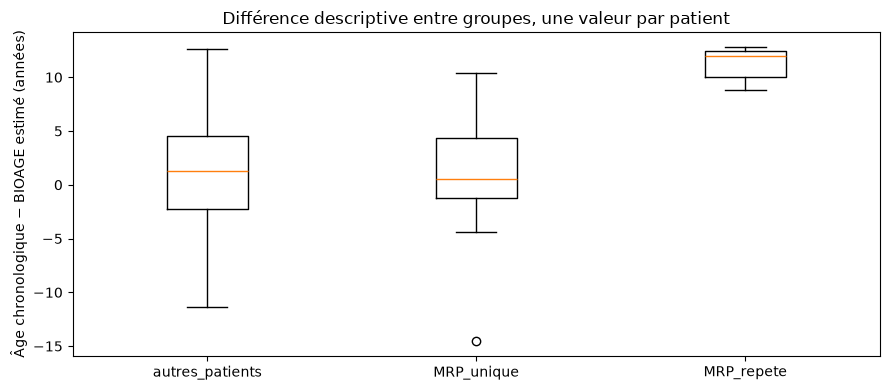

In [8]:
bioage_recit = sources_recit['observations'].loc[sources_recit['observations']['observation_code'].eq('BIOAGE')].copy()
bioage_recit['date_mesure'] = dates_recit(bioage_recit['observation_time'])
bioage_recit['bioage'] = nombres_recit(bioage_recit['numeric_value'], unite='years')
bioage_recit = bioage_recit.merge(patients_recit[['patient_number','naissance']], on='patient_number', validate='many_to_one')
bioage_recit['age_chronologique'] = (bioage_recit['date_mesure']-bioage_recit['naissance']).dt.total_seconds()/(365.2425*86400)
bioage_recit['ecart_age_estime'] = bioage_recit['age_chronologique']-bioage_recit['bioage']
ages_patients_recit = bioage_recit.groupby('patient_number')[['age_chronologique','ecart_age_estime']].mean().join(compte_mrp_recit).fillna({'nombre_actes_mrp':0})
ages_patients_recit['groupe'] = np.select([ages_patients_recit['nombre_actes_mrp'].gt(1), ages_patients_recit['nombre_actes_mrp'].eq(1)], ['MRP_repete','MRP_unique'], default='autres_patients')
resume_age_recit = ages_patients_recit.groupby('groupe').agg(patients=('ecart_age_estime','size'), age_chronologique_moyen=('age_chronologique','mean'), ecart_age_moyen=('ecart_age_estime','mean'), ecart_age_median=('ecart_age_estime','median'), ecart_type=('ecart_age_estime','std'))
display(resume_age_recit.round(3))
premier_mrp_recit = mrp_recit.groupby('patient_number')['date_acte'].min()
bioage_recit['premier_mrp'] = bioage_recit['patient_number'].map(premier_mrp_recit)
disponibilite_avant_recit = bioage_recit.loc[bioage_recit['patient_number'].isin(beneficiaires_repetes_recit['patient_number'])].assign(avant=lambda x:x['date_mesure'].lt(x['premier_mrp'])).groupby('patient_number')['avant'].any()
print('Patients répétés sans mesure BIOAGE antérieure au premier acte :', (~disponibilite_avant_recit).sum())
fig, axe = plt.subplots(figsize=(9,4))
groupes_ages_recit = ['autres_patients','MRP_unique','MRP_repete']
axe.boxplot([ages_patients_recit.loc[ages_patients_recit['groupe'].eq(g),'ecart_age_estime'].dropna() for g in groupes_ages_recit], tick_labels=groupes_ages_recit)
axe.set(ylabel='Âge chronologique − BIOAGE estimé (années)', title='Différence descriptive entre groupes, une valeur par patient')
plt.tight_layout()
plt.show()

Le groupe répété comprend huit patients, d'âge chronologique moyen 71,3 ans,
contre environ 50 ans dans les deux autres groupes. L'écart chronologique moins
BIOAGE estimé atteint en moyenne 11,32 ans, contre 1,10 pour les vingt patients
avec un acte unique et 1,01 pour les 212 autres. Cette divergence est nette
dans les données synthétiques, mais ne prouve pas un rajeunissement provoqué
par MRP-42 : les groupes diffèrent notamment par l'âge et trois des huit patients
n'ont aucune mesure BIOAGE antérieure au premier acte. L'hypothèse clinique
reste distincte de celle d'un phénotype atypique chez d'autres patients.

### Limite de la traçabilité matérielle et contrôle du décès public

Une chaîne d'organisations n'est pas une chaîne de lots. Nous vérifions si les
références de matériel MRP-42 correspondent directement à des références de
réception. Un résultat nul ne prouve pas l'absence de lien, seulement l'absence
d'une égalité de clé dans les champs comparés.
Le statut administratif « deceased » ne fournit pas une date. Pour Elira Vaun,
nous utilisons la date de fin du mandat public explicitement associé au décès,
sans la remplacer par une date supposée dans Health.

In [9]:
references_mrp_recit = set(mrp_recit['material_reference'].dropna())
references_reception_recit = set(sources_recit['receptions']['batch_reference'].dropna())
print('Références de matériel MRP-42 égales à une référence de lot réceptionné :', len(references_mrp_recit & references_reception_recit))
print('Exemples MRP-42 :', sorted(references_mrp_recit)[:5])
print('Exemples de lots réceptionnés :', sorted(references_reception_recit)[:5])
notices_deces_recit = sources_recit['nominations'].loc[sources_recit['nominations']['office_holder_name'].eq('Elira Vaun') & sources_recit['nominations']['departure_reason'].eq('deceased')]
display(notices_deces_recit[['appointment_record_id','office_holder_name','appointment_end','departure_reason']])
if len(notices_deces_recit) == 1:
    date_deces_public_recit = dates_recit(notices_deces_recit['appointment_end']).iloc[0]
    identifiant_elira_recit = beneficiaires_repetes_recit.loc[beneficiaires_repetes_recit['nom_complet'].eq('Elira Vaun'),'patient_number'].iloc[0]
    actes_elira_recit = mrp_recit.loc[mrp_recit['patient_number'].eq(identifiant_elira_recit), ['procedure_record_id','patient_number','date_acte','procedure_status']].copy()
    actes_elira_recit['apres_date_deces_public'] = actes_elira_recit['date_acte'].gt(date_deces_public_recit)
    display(actes_elira_recit)

Références de matériel MRP-42 égales à une référence de lot réceptionné : 0
Exemples MRP-42 : ['MTL-2014-0029', 'MTL-2015-0011', 'MTL-2016-0002', 'MTL-2016-0023', 'MTL-2016-0030']
Exemples de lots réceptionnés : ['B-2014-44545', 'B-2015-03133', 'B-2015-15126', 'B-2015-22943', 'B-2015-30475']


,appointment_record_id,office_holder_name,appointment_end,departure_reason
5,APT-000006,Elira Vaun,2021-09-18,deceased


,procedure_record_id,patient_number,date_acte,procedure_status,apres_date_deces_public
27,PRC-000028,PAT-31099,2014-07-18 09:05:00,completed,False
28,PRC-000029,PAT-31099,2016-07-29 09:05:00,completed,False
29,PRC-000030,PAT-31099,2018-08-10 09:05:00,completed,False


Aucune égalité de référence ne relie le matériel MRP-42 aux lots de réception
ERP. Les trois actes MRP-42 d'Elira Vaun sont datés de 2014, 2016 et 2018,
donc avant le décès public de septembre 2021. Cette vérification ne soutient
pas une hypothèse d'intervention post mortem ; le simple statut `deceased`
dans le fichier patient aurait été insuffisant pour l'affirmer.

## 6. Gouvernance et usage allégué : lire les sources positives et les contre-exemples

MEM-510100 décrit une procédure de traitement restreint. MEM-510101 apporte
un pont plus explicite vers une autorité désignée Unwabu et le bureau exécutif
de Meridian. Cela ne suffit pas à établir qu'Unwabu et une personne précise sont
une même identité. Le transport biologique et le programme clinique restent des
flux liés par des organisations, pas un mécanisme médical démontré.

In [10]:
for identifiant in ['MEM-510100','MEM-510101','PUB-510079']:
    lire_document_recit(identifiant)

### MEM-510100 — Secure Delivery Record-Handling Instruction

Source : `data/public_records/institutional_memos.csv`, date : 2023-08-17

SCOPE
This instruction applies to staff handling secure delivery records associated with shipment SHP-2022-00011 and related restricted consignments.

CONTROL REQUIREMENTS
Records marked CHAMELEO are to be routed through the designated compliance queue. Staff must verify the receiving facility code, named authorization class, seal number, and temperature-control record before release. Copies are not to be attached to ordinary customer correspondence. Route changes require approval from the security manager and the duty compliance officer.

RESPONSIBILITIES
Operations staff retain the ordinary shipment record. Security staff retain the sealed routing appendix. Warehouse staff record only the declared cargo category and quantity in the standard inventory system. Any mismatch between the standard record and the restricted appendix must be escalated rather than corrected locally.

ESCALATION
Contact the secure-delivery desk for missing signatures, unexplained destination changes, or requests to bypass the receiving scan. The code identifies a handling and governance procedure. This instruction does not explain the programme's wider purpose, the ownership of the designation, or the final use of any cargo.

### MEM-510101 — Restricted CHAMELEO Governance Review

Source : `data/public_records/institutional_memos.csv`, date : 2025-03-14

MEETING RECORD — RESTRICTED GOVERNANCE REVIEW

Attendees included the executive chair, the secure-delivery manager, clinical programme counsel, and the records secretary.

AGENDA
1. Authority for CHAMELEO routing.
2. Relationship between programme designation and executive approvals.
3. Separation of ordinary corporate records from restricted appendices.

DISCUSSION
The chair confirmed that Unwabu is the designation used in the restricted governance schedule for the authority approving CHAMELEO exceptions. The same schedule assigns final escalation to the Meridian executive office. Participants agreed that ordinary employees should see only shipment, inventory, and compliance fields needed for their roles. The secretary noted that earlier instructions treated CHAMELEO as a handling code, while the governance schedule links it to a named authority.

DECISIONS
The secure-delivery manager will maintain the restricted appendix. Compliance will retain a cross-reference between the designation, executive approvals, and affected routes. No change will be made to public corporate filings.

LIMITS
This record establishes an Unwabu–CHAMELEO–Meridian authority bridge. The meeting did not review other networks, biological questions, ecological material, or destination records.

The chair instructed staff not to alter existing operational records retrospectively. Any reconciliation should be recorded as a new governance note with a visible date and responsible role. The meeting did not review ecological evidence or clinical files, and participants were reminded that their authority was limited to routing and programme governance.

### PUB-510079 — Message Concerning Collected Eonycteris

Source : `data/public_records/public_and_investigative_documents.csv`, date : 2025-04-09

I worked on restricted receiving and reconciliation records. I am sending this because the standard files make the programme look like conservation support, but the handling instructions say something different.

The consignments include live or recently collected *Eonycteris spelaea*. They arrive under wildlife-monitoring or biological-sample descriptions, are consolidated in sealed units, and then disappear from the ordinary inventory sequence. I saw preparation sheets that used the word consumption and matched them to access cases, cold-storage receipts, and adjustment numbers. The animals were not being transferred only for tagging, veterinary examination, or habitat research.

Useful references include the spring Kestrel access file, the secure delivery series, and the biological-unit adjustments reviewed by the warehouse controller. Some copies use CHAMELEO routing, but I cannot explain who controls the entire programme. I did not see a complete destination record, and I cannot confirm the scale beyond the facilities where I worked.

Please verify the references independently. My account supports a consumption purpose for at least part of the collected bats. It does not establish the external route, the full network, or the historical origin of the programme.

## 7. Identité publique, phénotype et continuité historique

Les documents Health décrivent un phénotype inhabituel et une résolution vers
Elias Voss. Nous vérifions ce que le registre permet réellement de reproduire.
L'existence d'un dirigeant public est distincte de son égalité avec un patient.
Les similarités historiques de noms, d'associés ou de langage ne démontrent pas
qu'une personne a vécu plusieurs siècles.

In [11]:
dirigeants_recit = sources_recit['dirigeants'].copy()
dirigeants_recit['nom_normalise'] = normaliser_nom_recit(dirigeants_recit['full_name'])
voss_recit = dirigeants_recit.loc[dirigeants_recit['nom_normalise'].eq('elias voss')]
patient_cible_recit = patients_recit.loc[patients_recit['patient_number'].eq('PAT-31065')]
display(voss_recit[['filing_id','registration_number','full_name','birth_year_or_age_band','role_title','appointment_date']])
display(patient_cible_recit[['patient_number','nom_complet','naissance','home_region','occupation_text','primary_facility_license']])
print('Le nom, la naissance et la profession affichés ne reproduisent pas une égalité directe entre ces deux fiches.')
for identifiant in ['CLN-510027','CLN-510055','CLN-510064','CLN-510025','PUB-510043','PUB-510033','PUB-510044','PUB-510076']:
    lire_document_recit(identifiant)

,filing_id,registration_number,full_name,birth_year_or_age_band,role_title,appointment_date
3,FLG-000004,REG-VLN-01001,Dr. Elias Voss,1961,Executive chair of Meridian BioLogistics,1996-01-01


,patient_number,nom_complet,naissance,home_region,occupation_text,primary_facility_license
6,PAT-31065,Corin Hallen,1975-10-09,Valenne Republic,clinical specialist,FAC-VLN-101


Le nom, la naissance et la profession affichés ne reproduisent pas une égalité directe entre ces deux fiches.


### CLN-510027 — Targeted Thoracic Imaging Review

Source : `data/health/clinical_notes.csv`, date : 2023-04-11

INDICATION
Review of recurrent discordance between peripheral pulse measurements and apical recordings in a restricted patient, with comparison to the prior rhythm study.

TECHNIQUE
Targeted thoracic ultrasound and synchronized surface recording were performed in two acoustic windows. Device quality was acceptable. The study was repeated after repositioning because the initial waveform contained motion artefact.

FINDINGS
Two spatially distinct zones of contractile motion are visible. The dominant left-sided source follows the peripheral pulse. A second, smaller source is consistently located inferior and medial to the first and produces a pulsatile sequence that is not fully phase-locked to the dominant cycle. During the repeat acquisition, the interval between the two sources varied while each source retained internal periodicity. The finding was reproduced in both windows and was not abolished by lead replacement.

There is no acute chamber dilatation, effusion, or evidence of device displacement. The study cannot determine whether the second motion represents an accessory contractile structure, an unusual vascular phenomenon, or a stable anatomical variant.

IMPRESSION
Reproducible dual cardiac structures are considered as an imaging differential because two contractile sources are spatially separated and partly independent in timing. This wording describes the observed pattern rather than a final anatomical conclusion. Correlation with the paired signal recording, prior imaging, and specialist review is recommended.

... (17 outputs left out)

LEAD
Jacob Vale may be connected to an unusual clinical subject and to a set of historical aliases, but the chain remains incomplete.

EVIDENCE
A restricted clinical reference contains gait, ocular, and rhythm features that resemble the small physiological cluster identified in another facility. Public appointment and campaign records place Jacob Vale near organizations that repeatedly opposed extraction, warming, and closed ecological programmes. A 1962 meeting extract lists the same name alongside Jonah Bell and Julien Marot. Older correspondence uses related strategic phrases but does not name Vale directly.

LINKS
The clinical subject and the public figure share region, travel intervals, and an uncommon professional association. None of these is a secret identifier. The historical record supplies continuity of associates and language, not a biometric match. Sources disagree on the person's age and early career.

CONFIDENCE
Moderate for an institutional relationship; low to moderate for identity continuity. The evidence does not justify a species claim or a final account of the opposed networks.

NEXT STEPS
Obtain the original registry pages, compare independent photographs without relying on automated matching alone, and seek a second clinical record. Keep the Jacob hypothesis separate from the better-supported Voss linkage.

### PUB-510076 — Catalog Note on Recurrent Historical Identifiers

Source : `data/public_records/public_and_investigative_documents.csv`, date : 2025-02-05

PROVENANCE
This catalog note covers selected commercial, medical-enterprise, and natural-history papers dated 1911–1971. The originals come from three separately acquired collections and have not been merged physically.

CATALOG FINDING
Records attributed to Adrian Vosmere, Jonah Bell, and Julien Marot repeatedly use the Wren Street forwarding address, refer to the same two commercial associates, and employ the phrase “make the conditions ordinary” in discussions of routes and ecological infrastructure. Signature comparison is suggestive but not conclusive because several items are copies or secretary-written drafts. Travel intervals overlap less than expected for three independent advisers, yet the archive contains gaps large enough to permit ordinary explanations.

INTERPRETATION
The bundle justifies an alias-continuity hypothesis and provides a bridge for later identity-resolution work. It does not certify that the names represent one person, and it does not connect the historical records to a species classification. Researchers should cite the individual document references and preserve the distinction between recurring context and proof.

## 8. Classification alléguée, stratégies opposées et limites de l'inférence

PUB-510063 apporte le terme de classification « Chamaeleonidian » et une
hypothèse de transfert non terrestre. Nous rapportons ce que dit le document,
pas une identification biologique calculée à partir des signaux cardiaques.
Une absence dans les registres terrestres fournis ne démontre pas à elle seule
une destination extraterrestre, et aucun itinéraire précis n'est reconstitué ici.

PUB-510094 et les minutes de 1962 décrivent des stratégies écologiques opposées.
Les mesures de vergers montrent des associations avec l'activité des chauves-souris,
mais ne peuvent prouver une intention de réchauffement ou une manipulation
climatique par des acteurs particuliers.

In [12]:
for identifiant in ['PUB-510063','PUB-510094']:
    lire_document_recit(identifiant)
# Contre-exemples sémantiques et cliniques à conserver.
for identifiant in ['MEM-510089','PUB-510127','CLN-510126']:
    lire_document_recit(identifiant)

### PUB-510063 — Restricted Classification and External-Transfer Assessment

Source : `data/public_records/public_and_investigative_documents.csv`, date : 2025-05-16

PURPOSE
This briefing assesses two restricted terms that appear in separate analytical and handling records while preserving the limits of the available evidence.

CLASSIFICATION TERM
The word Chamaeleonidian appears in a restricted classification note associated with the unusual clinical population. The note is not a public taxonomy and does not provide an origin, population estimate, or complete mechanism. Its interpretation is supported indirectly by repeated physiology, public-identity inconsistencies, and historical continuity, but those supporting records remain distributed across different repositories.

EXTERNAL TRANSFER
Several handling records refer to an external destination that cannot be matched to ordinary terrestrial customs, port, aviation, or licensed-facility registries. One restricted note uses the expression non-terrestrial transfer. The absence of a terrestrial registry match, combined with specialized routing language, supports an external-transfer hypothesis. It does not identify the route, destination, carrier, volume, origin world, or total scale.

SOURCE ASSESSMENT
The classification term comes from a restricted record and is corroborated indirectly by several independent observations. The destination language is less direct: it appears in unmatched routing references and in a source account whose access was limited. These evidence classes should not be treated as equally certain. The species interpretation is stronger than any claim about where material ultimately travels.

ASSESSMENT
The two findings can be combined only at a high level: a concealed population is described with a non-human classification term, and some restricted movement is directed beyond ordinary terrestrial registries. The briefing does not explain who governs that movement, what is moved, or why. Historical causality, the number of individuals, and the precise external pathway remain unresolved.

HANDLING
Retain source references and uncertainty labels. Do not convert the external-transfer inference into a precise route claim or treat the classification note as a complete scientific description.

### PUB-510094 — Opposed Ecological Strategies and Disclosure

Source : `data/public_records/public_and_investigative_documents.csv`, date : 2024-07-12

QUESTION
Why do two groups using similar ecological language recommend sharply different forms of action?

METHOD
Public statements, campaign material, institutional memoranda, and research correspondence were coded for references to extraction, emissions, habitat thresholds, disclosure, and institutional control. The analysis focused on repeated phrases rather than individual names.

FINDINGS
One cluster argues that industrial extraction and warming must be reduced because ecological thresholds are being crossed. It favors public records, independent monitoring, and broad accountability. A second cluster also discusses ecological protection but repeatedly couples it with controlled access, continuity of selected programmes, and warnings that unrestricted disclosure could produce instability. The two clusters sometimes use the same evidence while proposing opposite governance responses.

Several documents associated with Jacob Vale fall within the anti-extraction cluster, but ordinary human advocates use overlapping language. Other records favor concealment or tightly managed disclosure without naming a single leader. The pattern supports opposed strategic networks and a tension over concealment; it does not establish the biological identity of any participant.

LIMITATIONS
Authorship is incomplete, some documents may be strategic messaging, and shared vocabulary does not prove common command. Network and historical analysis are required before stronger attribution.

The documents were also compared with ordinary climate campaigns. Human organizations frequently use the same terms—threshold, extraction, accountability, and public interest—without any connection to the restricted networks. The distinction therefore depends on relationships, timing, and policy choices rather than vocabulary alone. The research archive should preserve those ordinary controls when the corpus is analyzed.

Replication with a later, independently collected document set is recommended before assigning command relationships.

... (5 outputs left out)

PRIVATE NOTE
I returned from the meeting concerning meeting archive. The same advisers appeared, though their titles have changed. I cannot tell whether the similarity is habit, instruction, or coincidence. I have kept the address card with the travel papers.

PROVENANCE
Undated fragment, assigned to the approximate period from adjacent documents.

The archival item relates to meeting archive and is presented with provenance and transcription limits.

Names, dates, addresses, roles, and repeated phrases are recorded without converting resemblance into identity proof.

CATALOG COMMENT
Unwabu is written on the margin, apparently the name of a coastal vessel or a folklore reference; the context is unrelated to modern programme governance.

### CLN-510126 — Thoracic Imaging Report 07

Source : `data/health/clinical_notes.csv`, date : 2023-12-23

INDICATION
Imaging for executive health review in patient PAT-31099.

TECHNIQUE
Standard thoracic acquisition with repeat window after repositioning.

FINDINGS
Cardiac motion is regular overall. A transient secondary contour appeared in one view but was not reproducible after gain and position adjustment. No effusion or acute structural change is identified.

IMPRESSION
Technical or vascular overlap is favored. Correlation is recommended only if the clinical rhythm record remains discordant.

The record concerns executive health review and is limited to observations available to the clinical team.

Measurements were reviewed against prior visits, device quality, medication history, and ordinary technical explanations.

The assessment distinguishes reproducible findings from artefact and recommends correlation rather than categorical interpretation.

No acute deterioration was identified, and follow-up remains proportionate to the recorded functional risk.

DIFFERENTIAL NOTE
The phrase dual cardiac structures was entered in the preliminary worksheet but rejected after the apparent second contour disappeared on repeat positioning.

## 9. Schéma des liens réellement distingués

Les flèches pleines représentent les associations structurées retrouvées : flux
déclarés, licence, organisation, actes et fonction de dirigeant. Les flèches
pointillées représentent des affirmations documentaires. Le schéma ne suit pas
un même lot de bout en bout et ne donne aucun mécanisme biologique.

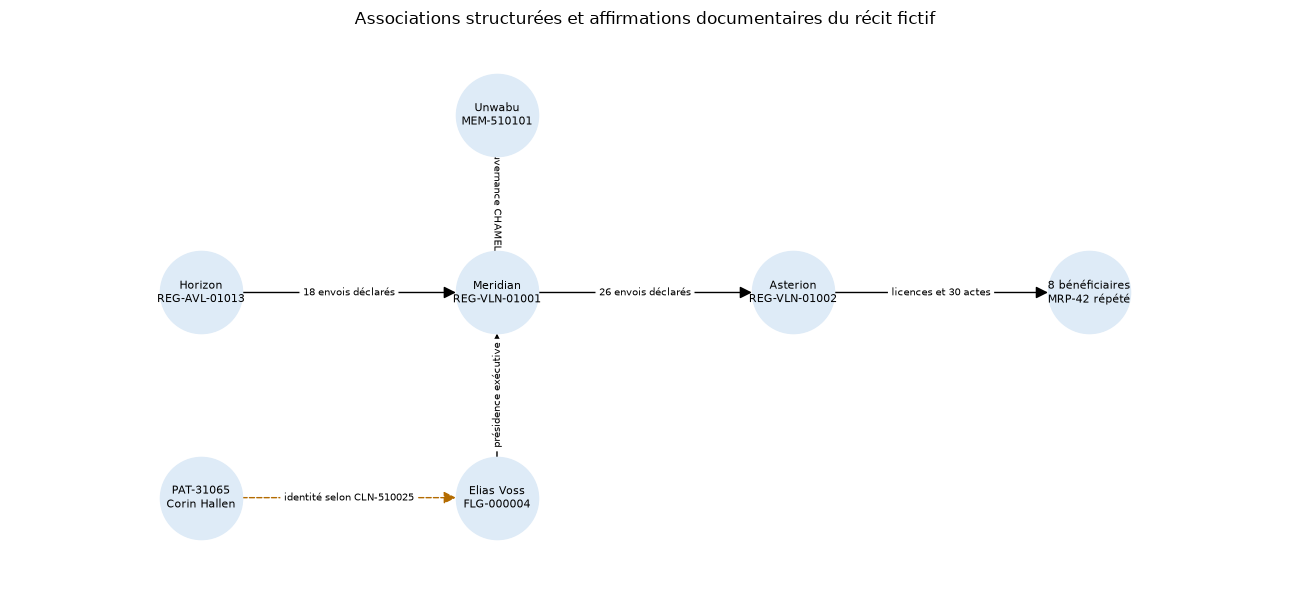

In [13]:
import networkx as nx

graphe_recit = nx.DiGraph()
liens_structures_recit = [
    ('Horizon\nREG-AVL-01013','Meridian\nREG-VLN-01001','18 envois déclarés'),
    ('Meridian\nREG-VLN-01001','Asterion\nREG-VLN-01002','26 envois déclarés'),
    ('Asterion\nREG-VLN-01002','8 bénéficiaires\nMRP-42 répété','licences et 30 actes'),
    ('Elias Voss\nFLG-000004','Meridian\nREG-VLN-01001','présidence exécutive')
]
liens_documentaires_recit = [
    ('Unwabu\nMEM-510101','Meridian\nREG-VLN-01001','gouvernance CHAMELEO'),
    ('PAT-31065\nCorin Hallen','Elias Voss\nFLG-000004','identité selon CLN-510025')
]
for u,v,label in liens_structures_recit+liens_documentaires_recit:
    graphe_recit.add_edge(u,v,label=label)
positions_recit = {
    'Horizon\nREG-AVL-01013':(0,1), 'Meridian\nREG-VLN-01001':(2,1),
    'Asterion\nREG-VLN-01002':(4,1), '8 bénéficiaires\nMRP-42 répété':(6,1),
    'Unwabu\nMEM-510101':(2,2.3), 'Elias Voss\nFLG-000004':(2,-.5),
    'PAT-31065\nCorin Hallen':(0,-.5)
}
fig, axe = plt.subplots(figsize=(13,6))
nx.draw_networkx_nodes(graphe_recit, positions_recit, ax=axe, node_size=3500, node_color='#deebf7')
nx.draw_networkx_labels(graphe_recit, positions_recit, ax=axe, font_size=8)
nx.draw_networkx_edges(graphe_recit, positions_recit, ax=axe, edgelist=[(u,v) for u,v,_ in liens_structures_recit], arrowsize=18, node_size=3500)
nx.draw_networkx_edges(graphe_recit, positions_recit, ax=axe, edgelist=[(u,v) for u,v,_ in liens_documentaires_recit], arrowsize=18, node_size=3500, style='dashed', edge_color='#b36b00')
nx.draw_networkx_edge_labels(graphe_recit, positions_recit, ax=axe, edge_labels=nx.get_edge_attributes(graphe_recit,'label'), font_size=7)
axe.set_title('Associations structurées et affirmations documentaires du récit fictif')
axe.margins(.15)
axe.axis('off')
plt.tight_layout()
plt.show()

## 10. Lecture d'ensemble et conclusions graduées

**Ce qui est directement recoupé dans les tables.** Horizon est associé aux accès
et aux envois écologiques. Meridian reçoit le flux écologique et expédie un flux
clinique vers Asterion. Les licences Health et les établissements ERP Asterion
convergent par organisation et nom. Huit personnes reçoivent des interventions
MRP-42 répétées, chez les mêmes prestataires, et présentent une divergence
descriptive entre âge biologique estimé et âge chronologique.

**Ce que les documents ajoutent.** Les sources décrivent une gouvernance restreinte
Unwabu–CHAMELEO–Meridian, l'usage de consommation pour une partie des chauves-souris,
un phénotype humain apparent inhabituel associé au nom Elias Voss, des continuités
d'alias historiques, et deux stratégies opposées sur l'extraction, le réchauffement
et la divulgation. Un briefing nomme la population cachée « Chamaeleonidian » et
évoque un transfert non terrestre avec un degré d'appui plus faible.

**Hypothèse narrative de travail.** Le projet semble mettre en scène un réseau
caché, associé à des identités publiques et à des intérêts de long terme, qui
s'appuie sur une infrastructure écologique, logistique et clinique. La collecte
d'Eonycteris, la consommation alléguée et le traitement de dirigeants constituent
des branches liées à des organisations communes. Les textes suggèrent un conflit
entre maintien discret du programme et opposition à l'extraction et au réchauffement.

**Ce que nous ne pouvons pas affirmer.** Aucun lot n'est suivi jusqu'à un patient,
aucun effet de rajeunissement n'est établi causalement, et les observations
physiologiques ne déterminent pas seules une espèce. L'égalité Voss–patient n'est
pas reproduite indépendamment dans les fiches structurées et leurs attributs
divergent. Les alias historiques et l'identité de Jacob Vale restent des pistes.
La destination extérieure, l'itinéraire, l'origine et l'ampleur du programme ne
sont pas établis. Unwabu est une désignation d'autorité dans un document, pas
une égalité prouvée avec un individu nommé. Les discordances de dates et d'unités
font partie des résultats, pas des détails à corriger pour rendre le récit cohérent.